<a href="https://colab.research.google.com/github/ashishkunche9-lab/blockchain-projects/blob/main/01-turbine-alarm-hashchain/alarm_log.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import hashlib, hmac, json, time, random

SECRET = b"plant-secret-key"

def make_hash(block):
    data = {k: block[k] for k in ("index", "time", "alarm", "value", "prev_hash")}
    msg = json.dumps(data, sort_keys=True).encode()
    return hmac.new(SECRET, msg, hashlib.sha256).hexdigest()

chain = []

def add_alarm(alarm, value):
    prev = chain[-1]["hash"] if chain else "0" * 64
    block = {"index": len(chain), "time": time.strftime("%Y-%m-%d %H:%M:%S"),
             "alarm": alarm, "value": value, "prev_hash": prev}
    block["hash"] = make_hash(block)
    chain.append(block)

def verify():
    for i, b in enumerate(chain):
        if b["hash"] != make_hash(b):
            return f"TAMPERED: block {i} data changed"
        if i > 0 and b["prev_hash"] != chain[i - 1]["hash"]:
            return f"BROKEN LINK at block {i}"
    return "Chain is valid"

# Simulated turbine sensor readings -> alarms when limits are crossed
random.seed(1)
limits = {"Vibration (mm/s)": ("high", 7.1),
          "Bearing temp (C)": ("high", 85),
          "Lube oil pressure (bar)": ("low", 1.5)}
history = {name: [] for name in limits}

for t in range(20):
    readings = {"Vibration (mm/s)": round(random.uniform(3, 9), 1),
                "Bearing temp (C)": round(random.uniform(70, 95), 1),
                "Lube oil pressure (bar)": round(random.uniform(1.0, 3.0), 2)}
    for name, val in readings.items():
        history[name].append(val)
        kind, lim = limits[name]
        if (kind == "high" and val > lim) or (kind == "low" and val < lim):
            add_alarm(name, val)

print(len(chain), "alarms stored.", verify())

21 alarms stored. Chain is valid


In [5]:
import copy
import pandas as pd
from IPython.display import display

def chain_table():
    rows = []
    for i, b in enumerate(chain):
        hash_ok = b["hash"] == make_hash(b)
        link_ok = (i == 0) or (b["prev_hash"] == chain[i - 1]["hash"])
        rows.append({"#": b["index"], "Alarm": b["alarm"], "Value": b["value"],
                     "Prev hash": b["prev_hash"][:8], "Hash": b["hash"][:8],
                     "Status": "OK" if hash_ok and link_ok else "TAMPERED"})
    return pd.DataFrame(rows)

def color(row):
    c = "#c8f7c5" if row["Status"] == "OK" else "#f7a5a5"
    return [f"background-color: {c}; color: black"] * len(row)

backup = copy.deepcopy(chain)

print("STEP 1: Original alarm log")
display(chain_table().head(8).style.apply(color, axis=1).hide(axis="index"))
print(verify())

chain[1]["value"] = 0.5
print("\nSTEP 2: Someone edits block 1")
display(chain_table().head(8).style.apply(color, axis=1).hide(axis="index"))
print(verify())

chain = copy.deepcopy(backup)

STEP 1: Original alarm log


#,Alarm,Value,Prev hash,Hash,Status
0,Bearing temp (C),91.200000,00000000,d7a54edf,OK
1,Bearing temp (C),89.700000,d7a54edf,efc52497,OK
2,Lube oil pressure (bar),1.190000,efc52497,0bc845a1,OK
3,Bearing temp (C),90.900000,0bc845a1,2b14be37,OK
4,Vibration (mm/s),7.600000,2b14be37,1ffd48e3,OK
5,Vibration (mm/s),7.300000,1ffd48e3,70c4d176,OK
6,Vibration (mm/s),8.400000,70c4d176,790c53b6,OK
7,Lube oil pressure (bar),1.050000,790c53b6,4fafc8d7,OK


Chain is valid

STEP 2: Someone edits block 1


#,Alarm,Value,Prev hash,Hash,Status
0,Bearing temp (C),91.200000,00000000,d7a54edf,OK
1,Bearing temp (C),0.500000,d7a54edf,efc52497,TAMPERED
2,Lube oil pressure (bar),1.190000,efc52497,0bc845a1,OK
3,Bearing temp (C),90.900000,0bc845a1,2b14be37,OK
4,Vibration (mm/s),7.600000,2b14be37,1ffd48e3,OK
5,Vibration (mm/s),7.300000,1ffd48e3,70c4d176,OK
6,Vibration (mm/s),8.400000,70c4d176,790c53b6,OK
7,Lube oil pressure (bar),1.050000,790c53b6,4fafc8d7,OK


TAMPERED: block 1 data changed


In [6]:
original = copy.deepcopy(chain)
anchor = original[-1]["hash"]

def verify_with_anchor():
    ok = "anchor OK" if chain[-1]["hash"] == anchor else "ANCHOR MISMATCH"
    return f"{verify()} | {ok}"

def rehash_attack():
    # Attacker doesn't know SECRET, so he can only use plain SHA-256
    chain[1]["value"] = 0.5
    for i in range(1, len(chain)):
        chain[i]["prev_hash"] = chain[i - 1]["hash"]
        data = {k: chain[i][k] for k in ("index", "time", "alarm", "value", "prev_hash")}
        chain[i]["hash"] = hashlib.sha256(
            json.dumps(data, sort_keys=True).encode()).hexdigest()

def test(name, change):
    global chain
    chain = copy.deepcopy(original)
    change()
    print(f"{name:22} -> {verify_with_anchor()}")

test("No change", lambda: None)
test("Edit a value", lambda: chain[1].update(value=0.5))
test("Edit alarm name", lambda: chain[0].update(alarm="Normal"))
test("Delete middle block", lambda: chain.pop(1))
test("Swap two blocks", lambda: chain.__setitem__(slice(0, 2), [chain[1], chain[0]]))
test("Delete last block", lambda: chain.pop())
test("Re-hash attack", rehash_attack)

chain = copy.deepcopy(original)


No change              -> Chain is valid | anchor OK
Edit a value           -> TAMPERED: block 1 data changed | anchor OK
Edit alarm name        -> TAMPERED: block 0 data changed | anchor OK
Delete middle block    -> BROKEN LINK at block 1 | anchor OK
Swap two blocks        -> BROKEN LINK at block 1 | anchor OK
Delete last block      -> Chain is valid | ANCHOR MISMATCH
Re-hash attack         -> TAMPERED: block 1 data changed | ANCHOR MISMATCH


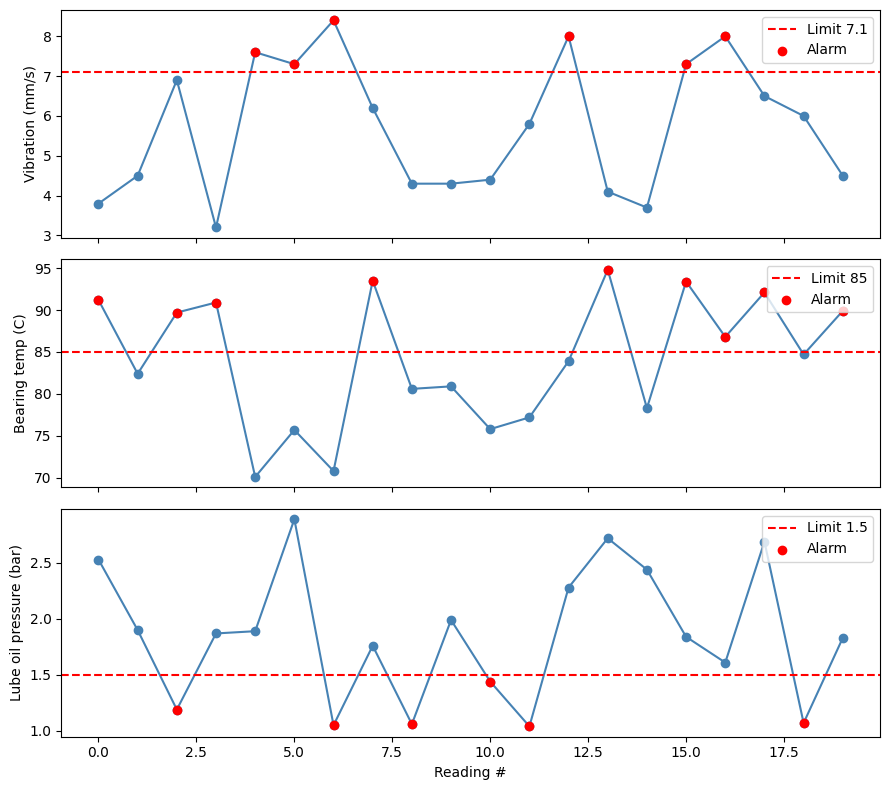

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (name, vals) in zip(axes, history.items()):
    kind, lim = limits[name]
    ax.plot(range(len(vals)), vals, marker="o", color="steelblue")
    ax.axhline(lim, color="red", linestyle="--", label=f"Limit {lim}")
    bad = [i for i, v in enumerate(vals)
           if (kind == "high" and v > lim) or (kind == "low" and v < lim)]
    ax.scatter(bad, [vals[i] for i in bad], color="red", zorder=3, label="Alarm")
    ax.set_ylabel(name)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Reading #")
plt.tight_layout()
plt.show()